In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
states = ["Low", "Medium", "High"]
actions = ["KEEP", "SWITCH"]

# Transition probabilities:
# P[current_state, action, next_state]
P = np.array([
    # Current state: Low
    [
        [0.8, 0.2, 0.0],  # KEEP
        [0.6, 0.3, 0.1]   # SWITCH
    ],

    # Current state: Medium
    [
        [0.3, 0.5, 0.2],  # KEEP
        [0.5, 0.4, 0.1]   # SWITCH
    ],

    # Current state: High
    [
        [0.1, 0.4, 0.5],  # KEEP
        [0.4, 0.4, 0.2]   # SWITCH
    ]
])

# Immediate rewards for each state-action pair
R = np.array([
    [5, 2],     # Low
    [1, 4],     # Medium
    [-5, 6]     # High
])

gamma = 0.9
theta = 0.001

print("States:", states)
print("Actions:", actions)
print("Discount factor:", gamma)

States: ['Low', 'Medium', 'High']
Actions: ['KEEP', 'SWITCH']
Discount factor: 0.9


In [3]:
V = np.zeros(len(states))
iteration = 0
value_history = []

while True:
    delta = 0
    new_V = V.copy()

    for s in range(len(states)):
        action_values = []

        for a in range(len(actions)):
            value = R[s, a] + gamma * np.sum(P[s, a] * V)
            action_values.append(value)

        new_V[s] = max(action_values)
        delta = max(delta, abs(new_V[s] - V[s]))

    V = new_V
    value_history.append(V.copy())
    iteration += 1

    if delta < theta:
        break

print("Converged after", iteration, "iterations")
print("\nOptimal State Values:")

for i, state in enumerate(states):
    print(f"{state}: {V[i]:.3f}")

Converged after 82 iterations

Optimal State Values:
Low: 47.989
Medium: 46.877
High: 48.964


In [4]:
policy = []

for s in range(len(states)):
    action_values = []

    for a in range(len(actions)):
        value = R[s, a] + gamma * np.sum(P[s, a] * V)
        action_values.append(value)

    best_action = np.argmax(action_values)
    policy.append(actions[best_action])

print("Optimal Traffic Signal Policy:\n")

for state, action in zip(states, policy):
    print(f"{state} traffic -> {action}")

Optimal Traffic Signal Policy:

Low traffic -> KEEP
Medium traffic -> SWITCH
High traffic -> SWITCH


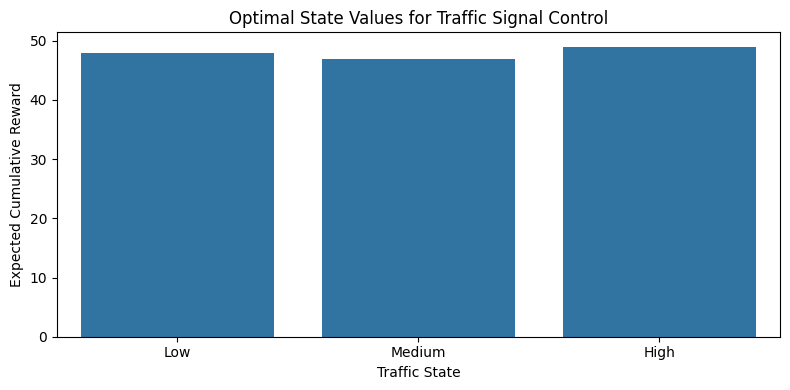

In [5]:
plt.figure(figsize=(8, 4))

sns.barplot(x=states, y=V)

plt.title("Optimal State Values for Traffic Signal Control")
plt.xlabel("Traffic State")
plt.ylabel("Expected Cumulative Reward")

plt.tight_layout()
plt.show()

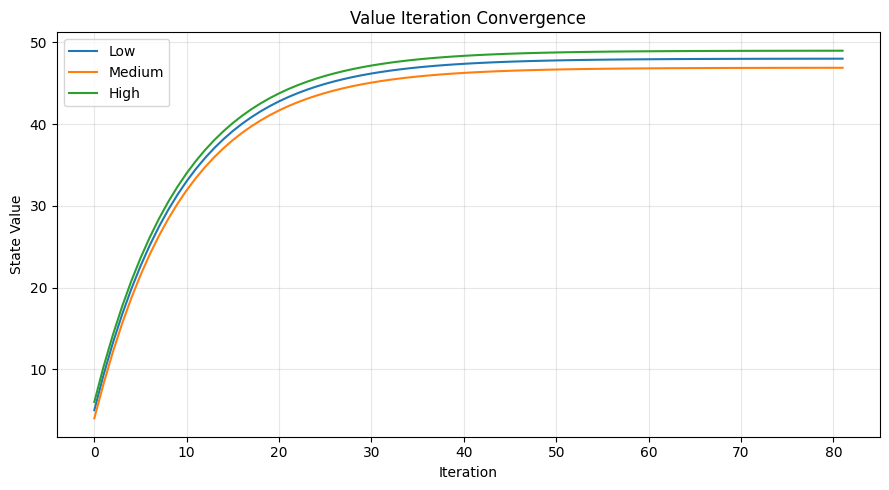

In [6]:
history = np.array(value_history)

plt.figure(figsize=(9, 5))

for i, state in enumerate(states):
    plt.plot(history[:, i], label=state)

plt.title("Value Iteration Convergence")
plt.xlabel("Iteration")
plt.ylabel("State Value")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
import pandas as pd
action_value_table = pd.DataFrame(
    {
        action: [
            R[s, a] + gamma * np.sum(P[s, a] * V)
            for s in range(len(states))
        ]
        for a, action in enumerate(actions)
    },
    index=states
)

display(action_value_table.round(3))

,KEEP,SWITCH
Low,47.990,44.978
Medium,43.865,46.877
High,38.229,48.965
